> **AI for RO · phase 2: a plant that follows the sun** — part of Project 3 of [chemai](https://github.com/EngMtaleb/chemai/tree/main/projects/p03_ai_for_ro). This notebook was written as “phase 2”: its code, its printed lines and the declaration appended at the end keep the names they were written with. Working names → the episode: phase 3 → **phase 1**, phase 3b → **phase 1B**, phase 4 → **phase 3**, phase 1 → **the lab study**; phase 2 keeps its number.

# A seawater RO plant that follows the sun — phase 2

**Question:** an RO plant meets a steady water demand. Panels power it by day; the grid covers the rest; a product-water tank
lets it make extra water while the sun shines. How much of its electricity can the sun cover? Does following the sun change
the energy per m³? Does a weather forecast help? What does warming the winter feed do? And what does each design cost?

**Two numbers, kept apart:** **kWh/m³** (how efficient the process is) and **the solar share** (how much of that electricity
comes from the sun). One can change without the other.

**Data (public):**
- Sun, air temperature and wind, hour by hour, 2015–2024, at a land point in Kuwait (29.37 N, 47.98 E), and the daily sea
  skin temperature at a point in the Gulf (29.0 N, 48.75 E) — NASA POWER ([power.larc.nasa.gov](https://power.larc.nasa.gov)).
- The membrane: FilmTec™ SW30HRLE-440 (8-inch, 41 m²). Its product data sheet (Form No. 45-D00969-en), the *Membrane System
  Design Guidelines for 8-inch FilmTec™ Elements* (Form No. 45-D01695-en, Rev. 14, 2026) and FilmTec's *Design Equations and
  Parameters* (Form No. 609-02057-604) — all public.

**What is not modelled** (the full list is at the end): dust on the panels, membrane fouling and ageing (phases 1 and 3), the wear
from starting and stopping trains, and any money made from surplus sun.

Run all: about ten minutes on Colab.

In [1]:
import subprocess, sys
try:
    import pvlib, gsw
except ImportError:                                   # Colab: two libraries to add
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib==0.15.2", "gsw"], check=True)
    import pvlib, gsw
import hashlib, json, time, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.sparse import coo_matrix, hstack, vstack, eye
pd.set_option("display.width", 200)
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "figure.facecolor": SURF, "axes.facecolor": SURF})
def style(ax):
    ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
print("pvlib", pvlib.__version__, "| gsw", gsw.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

pvlib 0.15.2 | gsw 3.6.23 | pandas 3.0.5 | numpy 2.5.3


## 1 · Download the sun and sea data and check them

Two requests to the NASA POWER API. Each file is checked against the SHA-256 of the copy used for this analysis (October 2026).
If NASA reprocesses its data, the check says so and the numbers below may move slightly.

In [2]:
API = "https://power.larc.nasa.gov/api/temporal/"
FILES = {
    "sun": (API + "hourly/point?parameters=ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,ALLSKY_SFC_SW_DIFF,CLRSKY_SFC_SW_DWN,T2M,WS10M"
                  "&community=RE&longitude=47.98&latitude=29.37&start=20150101&end=20241231&format=CSV&time-standard=UTC",
            "POWER_Point_Hourly_20150101_20241231_029d37N_047d98E_UTC.csv",
            "73b1e74e0f2472566cfbe3b1e5792c0fa38114ca72582f782990bed6f4dbab95"),
    "sea": (API + "daily/point?parameters=TS,T2M&community=RE&longitude=48.75&latitude=29.0&start=20150101&end=20241231&format=CSV",
            "POWER_Point_Daily_20150101_20241231_029d00N_048d75E_LST.csv",
            "a0bb8657a651064a1e5246573c4dd4f5ad19c5a13cb0314cf5642779cd887c37")}
D = Path("data"); D.mkdir(exist_ok=True)
for key, (url, name, sha) in FILES.items():
    f = D / name
    if not f.exists():
        f.write_bytes(urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=600).read())
    same = hashlib.sha256(f.read_bytes()).hexdigest() == sha
    print(f"{key}: {name}, {f.stat().st_size:,} bytes -",
          "the same file as this analysis" if same else "DIFFERENT from the file used here (NASA may have reprocessed it)")

def read_power(f):
    lines = f.read_text().splitlines()
    head = next(i for i, l in enumerate(lines) if l.startswith("-END HEADER-")) + 1
    return pd.read_csv(f, skiprows=head)

sun = read_power(D / FILES["sun"][1])
sun.index = pd.to_datetime(dict(year=sun.YEAR, month=sun.MO, day=sun.DY, hour=sun.HR), utc=True)
sun = sun.rename(columns={"ALLSKY_SFC_SW_DWN": "ghi", "ALLSKY_SFC_SW_DNI": "dni", "ALLSKY_SFC_SW_DIFF": "dhi",
                          "CLRSKY_SFC_SW_DWN": "ghi_clear", "T2M": "t_air", "WS10M": "wind"})
sea = read_power(D / FILES["sea"][1])
sea.index = pd.to_datetime(dict(year=sea.YEAR, month=sea.MO, day=sea.DY))
print(f"sun: {len(sun):,} hours, missing values: {int((sun[['ghi', 'dni', 'dhi', 'ghi_clear', 't_air', 'wind']] <= -999).sum().sum())}")
print(f"sea: {len(sea):,} days, missing values: {int((sea[['TS']] <= -999).sum().sum())}, "
      f"skin temperature {sea.TS.min():.1f} to {sea.TS.max():.1f} C")

sun: POWER_Point_Hourly_20150101_20241231_029d37N_047d98E_UTC.csv, 3,915,404 bytes - the same file as this analysis
sea: POWER_Point_Daily_20150101_20241231_029d00N_048d75E_LST.csv, 83,647 bytes - the same file as this analysis
sun: 87,672 hours, missing values: 0
sea: 3,653 days, missing values: 0, skin temperature 14.9 to 34.9 C


## 2 · What one kWp of panels gives, hour by hour

Declared before looking at results: fixed panels tilted 29° (the latitude), facing south; Hay–Davies sky model; cell temperature
from the SAPM model (open rack, glass/polymer) with the 10 m wind; PVWatts DC model with −0.4 %/°C; 14 % system losses and a 96 %
inverter (PVWatts defaults); DC/AC ratio 1.1. NASA POWER hour HR covers HR:00–HR+1:00 UTC, so the sun is placed at HR:30.
Times are then shown on the local clock (UTC+3). The result is the AC output of 1 kWp (DC) of panels.

In [3]:
LAT, LON, TILT, AZ, ALBEDO = 29.37, 47.98, 29.0, 180.0, 0.25
GAMMA, LOSSES, ETA_INV, DC_AC = -0.004, 0.14, 0.96, 1.1

def pv_per_kwp(d):
    sp = pvlib.solarposition.get_solarposition(d.index + pd.Timedelta(minutes=30), LAT, LON)
    sp.index = d.index
    poa = pvlib.irradiance.get_total_irradiance(TILT, AZ, sp.apparent_zenith, sp.azimuth, d.dni, d.ghi, d.dhi,
                                                dni_extra=pvlib.irradiance.get_extra_radiation(d.index),
                                                albedo=ALBEDO, model="haydavies")
    poa_g = poa["poa_global"].fillna(0).clip(lower=0)
    tp = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_polymer"]
    t_cell = pvlib.temperature.sapm_cell(poa_g, d.t_air, d.wind, **tp)
    pdc = pvlib.pvsystem.pvwatts_dc(poa_g, t_cell, pdc0=1.0, gamma_pdc=GAMMA) * (1 - LOSSES)
    pac = pvlib.inverter.pvwatts(pdc, pdc0=1.0 / DC_AC / ETA_INV, eta_inv_nom=ETA_INV).clip(lower=0).fillna(0)
    pdc_25 = pvlib.pvsystem.pvwatts_dc(poa_g, pd.Series(25.0, index=d.index), pdc0=1.0, gamma_pdc=GAMMA) * (1 - LOSSES)
    h = pd.DataFrame({"ghi": d.ghi / 1000, "ghi_clear": d.ghi_clear / 1000, "pv": pac, "pv_dc": pdc, "pv_dc_25C": pdc_25,
                      "t_air": d.t_air})
    h.index = h.index.tz_convert("Asia/Kuwait")
    return h

H = pv_per_kwp(sun)
daily = H.resample("D").agg({"ghi": "sum", "ghi_clear": "sum", "pv": "sum", "pv_dc": "sum", "pv_dc_25C": "sum"})
daily = daily[(daily.index.year >= 2015) & (daily.index.year <= 2024)]
yearly = daily.groupby(daily.index.year).pv.sum()
print(f"one kWp gives {yearly.mean():,.0f} kWh a year on average ({yearly.min():,.0f} to {yearly.max():,.0f})")
print("by year:", {int(k): round(float(v)) for k, v in yearly.items()})
print(f"lost to clouds: {100 * (1 - daily.ghi.sum() / daily.ghi_clear.sum()):.1f} % of the sunshine; "
      f"lost to heat: {100 * (1 - daily.pv_dc.sum() / daily.pv_dc_25C.sum()):.1f} % of the panel output")

one kWp gives 1,592 kWh a year on average (1,519 to 1,670)
by year: {2015: 1574, 2016: 1670, 2017: 1607, 2018: 1562, 2019: 1610, 2020: 1649, 2021: 1631, 2022: 1519, 2023: 1520, 2024: 1574}
lost to clouds: 5.3 % of the sunshine; lost to heat: 8.6 % of the panel output


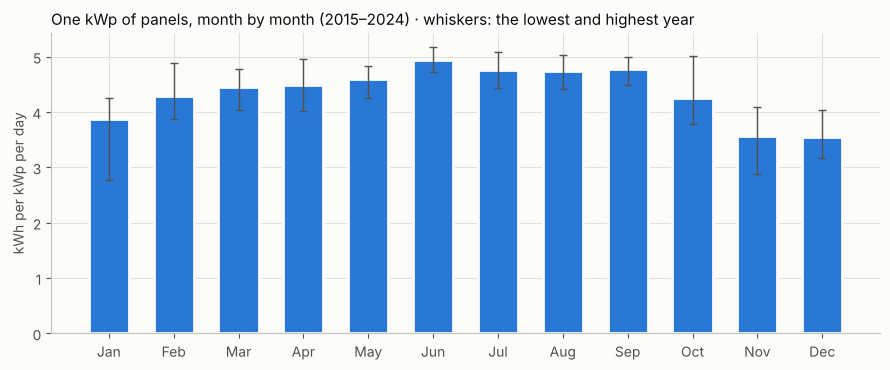

In [4]:
m = daily.assign(month=daily.index.month)
mon = m.groupby("month").agg(pv=("pv", "mean"))
per_year = m.groupby([m.index.year, "month"]).pv.mean().unstack(0)
names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(9, 3.8)); style(ax)
x = np.arange(12)
ax.bar(x, mon.pv, width=0.62, color=BLUE, edgecolor=SURF, linewidth=2)
ax.errorbar(x, mon.pv, yerr=[mon.pv - per_year.min(axis=1), per_year.max(axis=1) - mon.pv], fmt="none", ecolor=INK2, elinewidth=1, capsize=3)
ax.set_xticks(x, names); ax.set_ylabel("kWh per kWp per day")
ax.set_title("One kWp of panels, month by month (2015–2024) · whiskers: the lowest and highest year", loc="left", color=INK, fontsize=11)
plt.tight_layout(); plt.show()

## 3 · One pressure vessel: the physics and the membrane

Seven 8-inch elements in series (41 m² each), seawater at 43 g/L, 40 % recovery (35 % where the summer sea needs it, section 4).
- **Water and salt:** solution–diffusion, J = A (P − π(c_m) + π(c_p)), salt flux = B (c_m − c_p); each element is cut into
  20 slices and the flux in each slice is solved exactly (bisection).
- **Osmotic pressure** of NaCl: π = (0.741829 c + 0.00111004 c²) × (273.15 + T) / 298.15 (bar, c in g/L). The relation is the
  one used in the lab study (Sitterley et al. 2025), taken as valid at 25 °C and scaled with absolute temperature (van 't Hoff),
  as FilmTec's own design equation is (π = 1.12 (273 + T) Σm, psi).
- **Temperature and the membrane:** FilmTec's correction factor TCF = exp(K (1/298.15 − 1/(273.15 + T))), K = 2640 at or
  above 25 °C, 3020 below; A and B both scale with it.
- **Polarisation** (salt piling up at the membrane): FilmTec's exp(0.7 × the element's recovery).
- **Pressure drop** per element: FilmTec's 0.01 q^1.7 psi (q in gpm).
- **Energy:** the high-pressure pump (90 %, Lin & Veerapaneni 2021) lifts the permeate-equivalent flow from 0 bar; an isobaric
  energy-recovery device (96 %, Schunke et al. 2020) returns the brine pressure; a booster (90 %, assumed) tops it up; motors
  95 % (assumed). This is the RO's own energy; the rest of the plant comes in section 5.
- **Limits** (8-inch FilmTec guidelines, seawater, open intake, SDI < 5): lead element recovery ≤ 13 %; lead element flux ≤ 32 LMH (the lead
  element has the highest flux in the vessel); feed ≤ 14 m³/h and brine ≥ 3.4 m³/h per vessel; ≤ 83 bar; ≤ 1 bar drop per
  element; product ≤ 500 mg/L.

In [5]:
AREA_EL, GPM_PER_M3H, PSI_PER_BAR = 41.0, 4.402868, 14.5038
ETA_HP, ETA_ERD, ETA_BP, ETA_MOTOR = 0.90, 0.96, 0.90, 0.95
LIM = dict(el_recovery=0.13, el_flux=32.0, q_feed_max=14.0, q_brine_min=3.4, p_max=83.0, el_dp_max=1.0)
MEM = {"A20": 1.097, "B20": 0.0773}                    # phase 1 values; refitted to the datasheet below

def tcf(T):
    return float(np.exp((2640.0 if T >= 25 else 3020.0) * (1 / 298.15 - 1 / (273.15 + T))))

def pi_bar(c, T):
    """Osmotic pressure of NaCl, bar: the phase-1 relation at 25 C, scaled with absolute temperature."""
    return (0.741829 * c + 0.00111004 * c ** 2) * (273.15 + T) / 298.15

def solve_flux(P_loc, cm, A, B, T, iters=50):
    lo, hi = np.zeros_like(P_loc), np.maximum(A * P_loc, 1e-9)
    for _ in range(iters):
        J = (lo + hi) / 2
        f = J - A * (P_loc - pi_bar(cm, T) + pi_bar(B * cm / (J + B), T))
        hi, lo = np.where(f > 0, J, hi), np.where(f > 0, lo, J)
    J = (lo + hi) / 2
    return J, B * cm / (J + B)

def vessel(P, Qf, c_f, T, n=7, slices=20, y_iters=12):
    """Feed pressures P (bar) and feed flows Qf (m3/h), arrays of one shape -> what each vessel gives."""
    k = tcf(T) / tcf(20.0)
    A, B = MEM["A20"] * k, MEM["B20"] * k
    P = np.asarray(P, float).copy(); Q = np.asarray(Qf, float) * np.ones_like(P); Q_f = Q.copy()
    c = np.full_like(P, float(c_f)); dA = AREA_EL / slices
    rec, flux, perm, cpm, dps = [], [], [], [], []
    Y = np.full_like(P, 0.08)
    for e in range(n):
        for _ in range(y_iters):                      # the element's recovery sets its polarisation and pressure drop
            pf = np.exp(0.7 * Y)
            dP = 0.01 * (Q * (1 - Y / 2) * GPM_PER_M3H) ** 1.7 / PSI_PER_BAR
            Qi, ci = Q.copy(), c.copy()
            qp_el, salt_el = np.zeros_like(P), np.zeros_like(P)
            for s_ in range(slices):
                P_loc = P - dP * (s_ + 0.5) / slices
                J, cp = solve_flux(P_loc, ci * pf, A, B, T)
                qp = np.minimum(J * dA / 1000.0, 0.95 * Qi)
                ci = (Qi * ci - qp * cp) / (Qi - qp); Qi = Qi - qp
                qp_el += qp; salt_el += qp * cp
            Y = qp_el / Q
        rec.append(Y.copy()); flux.append(1000 * qp_el / AREA_EL); perm.append(qp_el.copy())
        cpm.append(1000 * salt_el / np.maximum(qp_el, 1e-12)); dps.append(dP.copy())
        P, Q, c = P - dP, Qi, ci
        cp_last = cp
    perm, cpm = np.array(perm), np.array(cpm)
    Qp = perm.sum(0); pf_last = np.exp(0.7 * rec[-1])
    return dict(Q_p=Qp, recovery=Qp / Q_f, c_p_mgL=(perm * cpm).sum(0) / np.maximum(Qp, 1e-12), P_brine=P, Q_brine=Q,
                c_brine=c, ndp_tail=P - (pi_bar(c * pf_last, T) - pi_bar(cp_last, T)), lead_recovery=rec[0], lead_flux=flux[0],
                max_el_dp=np.max(dps, 0))

def sec_ro(P_f, Q_f, Q_p, P_b):
    """kWh per m3 of permeate: pump on the permeate-equivalent flow, booster on the rest after the isobaric device.
    bar x m3/h / 36 = kW."""
    hp = Q_p * P_f / ETA_HP
    bp = (Q_f - Q_p) * max(P_f - ETA_ERD * P_b, 0) / ETA_BP
    return (hp + bp) / ETA_MOTOR / 36.0 / Q_p

def operate(fluxes, R, c_f, T, n=7):
    """The feed pressure that gives each average flux (LMH) at recovery R; None where it would need > 83 bar."""
    fluxes = np.asarray(fluxes, float); m = len(fluxes)
    Q_p = fluxes * n * AREA_EL / 1000.0; Q_f = Q_p / R
    lo, hi, alive = np.full(m, 0.5 * pi_bar(c_f, T)), np.full(m, LIM["p_max"]), np.ones(m, bool)
    for _ in range(3):                                # scan 41 pressures, then zoom in twice
        grid = np.array([np.linspace(lo[i], hi[i], 41) for i in range(m)])
        q = vessel(grid, Q_f[:, None] * np.ones((1, 41)), c_f, T, n)["Q_p"]
        for i in range(m):
            if alive[i] and q[i, -1] < Q_p[i]:
                alive[i] = False
            elif alive[i]:
                j = int(np.argmax(q[i] >= Q_p[i])); lo[i], hi[i] = grid[i, max(j - 1, 0)], grid[i, j]
    q_lo, q_hi = vessel(lo, Q_f, c_f, T, n)["Q_p"], vessel(hi, Q_f, c_f, T, n)["Q_p"]
    P_f = np.array([float(np.interp(Q_p[i], [q_lo[i], q_hi[i]], [lo[i], hi[i]])) for i in range(m)])
    v = vessel(P_f, Q_f, c_f, T, n)
    out = []
    for i in range(m):
        if not alive[i]:
            out.append(None); continue
        d = {k: x[i] for k, x in v.items()}
        d.update(P_f=float(P_f[i]), Q_f=float(Q_f[i]), flux=float(fluxes[i]), T=T, R=R,
                 sec_ro=sec_ro(float(P_f[i]), float(Q_f[i]), float(d["Q_p"]), float(d["P_brine"])))
        out.append(d)
    return out

def flags(v):
    f = []
    if v["lead_recovery"] > LIM["el_recovery"]: f.append("lead recovery")
    if v["lead_flux"] > LIM["el_flux"]: f.append("lead flux")
    if v["Q_f"] > LIM["q_feed_max"]: f.append("feed flow")
    if v["Q_brine"] < LIM["q_brine_min"]: f.append("brine flow")
    if v["max_el_dp"] > LIM["el_dp_max"]: f.append("element dP")
    if v["ndp_tail"] < 0: f.append("tail NDP < 0")
    return ", ".join(f) or "ok"

**The membrane, fitted to its datasheet.** The SW30HRLE-440 data sheet test: 32 g/L NaCl, 55.2 bar (800 psi), 25 °C, 8 % recovery →
30.2 m³/d and 99.80 % rejection. A and B are adjusted until one element reproduces both.

In [6]:
def element_at_test():
    lo, hi = 1.0, 40.0
    for _ in range(40):                               # the feed flow that gives 8 % recovery
        q = (lo + hi) / 2
        v = vessel(np.array([55.16]), np.array([q]), 32.0, 25.0, n=1)
        lo, hi = (lo, q) if v["recovery"][0] < 0.08 else (q, hi)
    v = vessel(np.array([55.16]), np.array([(lo + hi) / 2]), 32.0, 25.0, n=1)
    return 24 * float(v["Q_p"][0]), 100 * (1 - float(v["c_p_mgL"][0]) / 1000 / 32.0)

for _ in range(12):
    q, rej = element_at_test()
    MEM["A20"] *= 30.2 / q
    MEM["B20"] *= (100 - 99.80) / (100 - rej)
q, rej = element_at_test()
print(f"A = {MEM['A20']:.4f} LMH/bar, B = {MEM['B20']:.4f} LMH at 20 C  ->  {q:.2f} m3/d and {rej:.2f} % rejection at the datasheet test")

A = 0.9471 LMH/bar, B = 0.0470 LMH at 20 C  ->  30.20 m3/d and 99.80 % rejection at the datasheet test


In [7]:
rows = []
for T, R in ((15.0, 0.40), (25.0, 0.40), (33.0, 0.40), (35.0, 0.40), (35.0, 0.35)):
    v = operate([14.0], R, 43.0, T)[0]
    rows.append({"sea, C": T, "recovery %": 100 * R, "feed bar": v["P_f"], "RO kWh/m3": v["sec_ro"],
                 "permeate mg/L": float(v["c_p_mgL"]), "lead flux LMH": float(v["lead_flux"]),
                 "lead recovery %": 100 * float(v["lead_recovery"]), "brine m3/h": float(v["Q_brine"]), "limits": flags(v)})
print("The design point: 7 elements, 14 LMH, 43 g/L")
display(pd.DataFrame(rows).round(2))

The design point: 7 elements, 14 LMH, 43 g/L


,"sea, C",recovery %,feed bar,RO kWh/m3,permeate mg/L,lead flux LMH,lead recovery %,brine m3/h,limits
0,15.0,40.0,66.54,2.38,171.11,23.24,9.49,6.03,ok
1,25.0,40.0,63.97,2.29,247.85,27.63,11.28,6.03,ok
2,33.0,40.0,63.44,2.27,316.22,31.37,12.81,6.03,ok
3,35.0,40.0,63.39,2.27,335.31,32.36,13.21,6.03,"lead recovery, lead flux"
4,35.0,35.0,59.87,2.23,312.79,29.29,10.46,7.46,ok


## 4 · The operating window: how far one train can turn down or up

Each train is computed at every sea temperature from 15 to 35 °C (2 °C steps) and every average flux from 6 to 17 LMH
(43 % to 121 % of the design output), with the recovery held at 40 %. Where the hot sea leaves no usable design point at 40 %,
the train drops to 35 % recovery (a choice made before the runs). A point is usable only inside every limit, with product
≤ 500 mg/L. **17 LMH is our own ceiling**: it assumes pumps sized for 121 % of the design flow; in cold water the membrane
limits alone would allow more.

In [8]:
t0 = time.time()
FLUXES = list(range(6, 18))

def table(R, temps):
    rows = []
    for T in temps:
        for flux, v in zip(FLUXES, operate(FLUXES, R, 43.0, float(T))):
            if v is None:
                rows.append(dict(T=T, R=R, flux=flux, note="needs > 83 bar")); continue
            rows.append(dict(T=T, R=R, flux=flux, P_f=v["P_f"], sec_ro=v["sec_ro"], c_p=float(v["c_p_mgL"]),
                             lead_flux=float(v["lead_flux"]), lead_rec=100 * float(v["lead_recovery"]),
                             Q_brine=float(v["Q_brine"]), note=flags(v)))
    d = pd.DataFrame(rows)
    d["ok"] = (d.note == "ok") & (d.c_p <= 500)
    return d

TEMPS = [float(T) for T in np.arange(15.0, 35.1, 2.0)]
p40 = table(0.40, TEMPS)
design_ok = p40[p40.flux == 14].set_index("T").ok
HOT = [T for T in TEMPS if not design_ok[T]]
p35 = table(0.35, HOT)
perf = pd.concat([p40[~p40["T"].isin(HOT)], p35], ignore_index=True)
perf["f"] = perf.flux / 14.0
print(f"{len(p40) + len(p35)} points in {time.time() - t0:.0f} s; 35 % recovery at: {HOT} C")
win = perf[perf.ok].groupby("T").agg(recovery=("R", "first"), lowest_LMH=("flux", "min"), highest_LMH=("flux", "max"))
display(win.T)

144 points in 113 s; 35 % recovery at: [35.0] C


T,15.0,17.0,19.0,21.0,23.0,25.0,27.0,29.0,31.0,33.0,35.0
recovery,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.35
lowest_LMH,8.0,8.0,8.0,9.0,10.0,11.0,11.0,12.0,13.0,14.0,9.00
highest_LMH,17.0,17.0,17.0,17.0,17.0,17.0,17.0,16.0,15.0,14.0,16.00


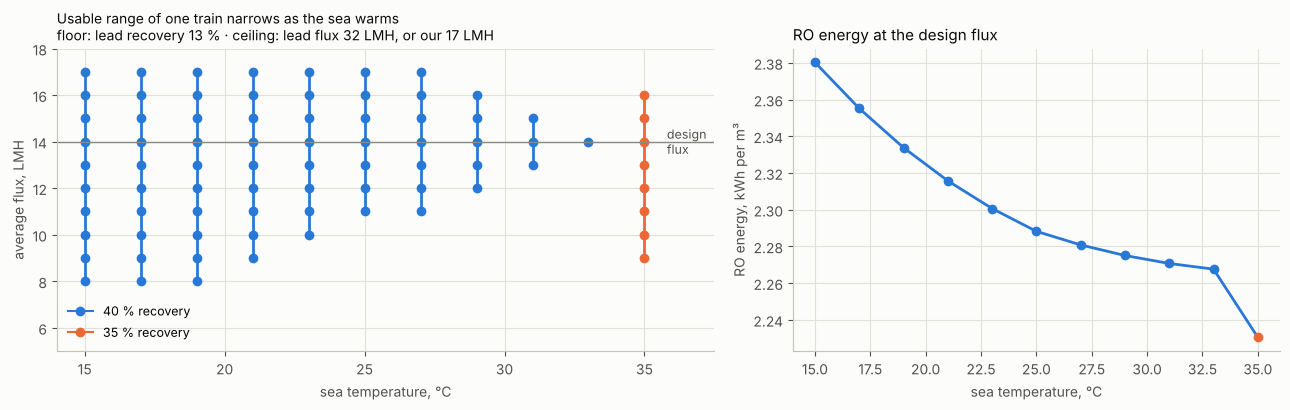

In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.35, 1]}); style(a); style(b)
for T, g in perf.groupby("T"):
    u = g[g.ok].flux; col = ORANGE if g.R.iloc[0] < 0.40 else BLUE
    a.plot([T, T], [u.min(), u.max()], color=col, lw=2)
    a.plot(np.full(len(u), T), u, "o", color=col, ms=6)
a.axhline(14, color=MUTED, lw=1); a.text(35.8, 14, "design\nflux", color=INK2, fontsize=9, va="center")
a.plot([], [], "o-", color=BLUE, label="40 % recovery"); a.plot([], [], "o-", color=ORANGE, label="35 % recovery")
a.legend(frameon=False, fontsize=9, loc="lower left")
a.set_xlim(14, 37.5); a.set_xlabel("sea temperature, °C"); a.set_ylabel("average flux, LMH"); a.set_ylim(5, 18)
a.set_title("Usable range of one train narrows as the sea warms\n"
            "floor: lead recovery 13 % · ceiling: lead flux 32 LMH, or our 17 LMH", loc="left", color=INK, fontsize=10)
d14 = perf[perf.flux == 14].sort_values("T")
b.plot(d14["T"], d14.sec_ro, "-", color=BLUE, lw=2)
for _, r in d14.iterrows():
    b.plot(r["T"], r.sec_ro, "o", color=ORANGE if r.R < 0.40 else BLUE, ms=6)
b.set_xlabel("sea temperature, °C"); b.set_ylabel("RO energy, kWh per m³")
b.set_title("RO energy at the design flux", loc="left", color=INK, fontsize=11)
plt.tight_layout(); plt.show()

## 5 · A year, hour by hour

**The plant**, per 1,000 m³/day of demand, delivered evenly round the clock (41.7 m³/h): 8 identical trains;
**capacity** = the plant's output at design flux ÷ demand. Each train runs inside its window from section 4. At any output the
trains share the load equally (the lowest-energy way); below 8 × the lowest point, trains stop, and part of a train in an hour
stands for a train running part of that hour. (At 1,000 m³/day a "train" is only 1–3 vessels; only the count of 8 matters.)
**Energy** = the RO energy above + the rest of the plant (intake, pretreatment, post-treatment, services), taken as a fixed amount
per m³ made: the RO is about 65 % of a seawater RO plant's energy (Schunke et al. 2020), applied at the design point; at 35 %
recovery the rest is raised by 40/35, because intake and pretreatment handle more feed per m³.
**Sun:** the panels' AC output; no batteries — sun not used in its hour is lost. **Tank:** the city is never short.

**Strategies**
- **steady:** make the demand every hour; the sun when it shines, the grid otherwise.
- **rule (no forecast):** by day use all the sun the tank can take; at night empty the tank first, then produce.
- **plan, tomorrow = today:** each midnight plan the next 48 h by linear programming, with yesterday's sun as the forecast;
  run the first 24 h with the sun that really comes.
- **plan, perfect 48-h forecast:** the same plan with the next 48 h of sun known exactly.

Both plans carry a small penalty on changing the output (0.02 kWh per m³/h of change), so that they do not switch trains
every hour; without it they would buy the same grid energy and switch trains about three times as often.

In [10]:
DEMAND, TRAINS, C_P_MAX, RO_SHARE, RAMP_COST = 1000.0 / 24.0, 8, 500.0, 0.65, 0.02
g = perf[(perf.f.round(4) == 1.0) & (perf.R == 0.40)].sort_values("T")
OTHER = float(np.interp(25.0, g["T"], g["sec_ro"])) * (1 - RO_SHARE) / RO_SHARE
print(f"rest of the plant: {OTHER:.2f} kWh/m3 at 40 % recovery, {OTHER * 0.40 / 0.35:.2f} at 35 %")

def curves(C):
    """For each table temperature: the plant's lowest-energy curve (output q -> energy E), salinity, limits."""
    Q_tr = C * DEMAND / TRAINS
    out = {}
    for T, gT in perf.groupby("T"):
        R = float(gT.R.iloc[0]); other = OTHER * 0.40 / R
        ok = gT[gT.ok].sort_values("f")
        assert not ok.empty, f"no usable point at {T} C"
        q = np.array([0.0] + list(TRAINS * Q_tr * ok.f))
        E = np.array([0.0] + list(TRAINS * Q_tr * ok.f * (ok.sec_ro + other)))
        cp = np.array([float(ok.c_p.iloc[0])] + list(ok.c_p))
        assert np.all(np.diff(np.diff(E) / np.diff(q)) > -1e-9), "energy curve not convex"
        out[float(T)] = dict(q=q, E=E, cp=cp, q_max=q[-1], f_min=float(ok.f.iloc[0]), Q_tr=Q_tr, R=R)
    return out

def sun_sea(year):
    pv = H.pv[H.index.year == year]
    T = pd.Series(pv.index.tz_localize(None).normalize(), index=pv.index).map(sea.TS)
    return pv.to_numpy(float), T.to_numpy(float), pv.index

def nearest(cv, T):
    keys = np.array(sorted(cv))
    return cv[float(keys[np.argmin(np.abs(keys - T))])]

def groups(cv, T):
    keys = np.array(sorted(cv))
    return keys, np.abs(T[:, None] - keys[None, :]).argmin(1)

def run_steady(pv_kw, T, cv, S_max):
    return np.full(len(pv_kw), DEMAND)

def run_rule(pv_kw, T, cv, S_max):
    keys, k = groups(cv, T)
    n = len(pv_kw); q_sun, q_max = np.zeros(n), np.zeros(n)
    for j, key in enumerate(keys):
        m = k == j; c = cv[float(key)]
        q_sun[m] = np.interp(pv_kw[m], c["E"], c["q"]); q_max[m] = c["q_max"]
    q, S = np.zeros(n), 0.0
    for t in range(n):
        qt = min(max(q_sun[t], DEMAND - S), q_max[t], S_max - S + DEMAND) if pv_kw[t] > 0 else max(0.0, DEMAND - S)
        q[t] = qt; S += qt - DEMAND
    return q

def plan_lp(pv_h, T_h, cv, S0, S_max, q_prev):
    """Least grid energy (+ RAMP_COST per m3/h of change). Per hour: output, energy, sun used, grid, tank, up, down."""
    Hn = len(pv_h); cs = [nearest(cv, T) for T in T_h]; n = 7 * Hn
    iq, ie, iu, ig, iS, iup, idn = (np.arange(Hn) + k * Hn for k in range(7))
    cost = np.zeros(n); cost[ig] = 1.0; cost[iq] = 1e-6; cost[iup] = RAMP_COST; cost[idn] = RAMP_COST
    rows, cols, vals, b_ub, r = [], [], [], [], 0
    for t, c in enumerate(cs):
        sl = np.diff(c["E"]) / np.diff(c["q"]); ic = c["E"][:-1] - sl * c["q"][:-1]
        for s_, i0 in zip(sl, ic):                    # energy >= every segment of the convex curve
            rows += [r, r]; cols += [iq[t], ie[t]]; vals += [s_, -1.0]; b_ub.append(-i0); r += 1
    rows.append(r); cols.append(iS[Hn - 1]); vals.append(-1.0); b_ub.append(-S0); r += 1      # end tank >= start tank
    A_ub = coo_matrix((vals, (rows, cols)), shape=(r, n))
    Z, I, D_sh = coo_matrix((Hn, Hn)), eye(Hn), eye(Hn) - eye(Hn, k=-1)
    A_eq = vstack([hstack([Z, I, -I, -I, Z, Z, Z]),                 # energy = sun used + grid
                   hstack([-I, Z, Z, Z, D_sh, Z, Z]),               # tank(t) - tank(t-1) = output - demand
                   hstack([D_sh, Z, Z, Z, Z, -I, I])])              # output(t) - output(t-1) = up - down
    be = [0.0] * Hn + [-DEMAND + S0] + [-DEMAND] * (Hn - 1) + [q_prev] + [0.0] * (Hn - 1)
    bounds = ([(0, c["q_max"]) for c in cs] + [(0, None)] * Hn + [(0, p) for p in pv_h] + [(0, None)] * Hn
              + [(0, S_max)] * Hn + [(0, None)] * (2 * Hn))
    res = linprog(cost, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=be, bounds=bounds, method="highs")
    assert res.status == 0, res.message
    return res.x[iq]

def run_plan(pv_kw, T, cv, S_max, known=True, horizon=48):
    n = len(pv_kw); q, S = np.zeros(n), 0.0
    for a in range(0, n, 24):
        b = min(a + horizon, n)
        if known:
            pv_h = pv_kw[a:b]
        else:
            last = pv_kw[a - 24:a] if a >= 24 else pv_kw[a:a + 24]
            pv_h = np.tile(last, int(np.ceil((b - a) / len(last))))[: b - a]
        x = plan_lp(pv_h, T[a:b], cv, S, S_max, q[a - 1] if a > 0 else DEMAND)
        for t in range(min(24, n - a)):
            q[a + t] = x[t]; S += x[t] - DEMAND
    return q

def hourly(q, T, cv):
    keys, k = groups(cv, T)
    E, cp, n_on = np.zeros(len(q)), np.zeros(len(q)), np.zeros(len(q), int)
    for j, key in enumerate(keys):
        m = k == j; c = cv[float(key)]
        E[m] = np.interp(q[m], c["q"], c["E"]); cp[m] = np.interp(q[m], c["q"], c["cp"])
        unit = c["f_min"] * c["Q_tr"]
        n_on[m] = np.where(q[m] <= 1e-9, 0, np.where(q[m] >= TRAINS * unit - 1e-9, TRAINS, np.ceil(q[m] / unit - 1e-9))).astype(int)
    return E, cp, n_on

def score(q, pv_kw, T, cv):
    E, cp, n_on = hourly(q, T, cv)
    used = np.minimum(E, pv_kw); S = np.cumsum(q - DEMAND); water = q.sum()
    return {"kWh/m3": E.sum() / water, "solar share %": 100 * used.sum() / E.sum(), "grid kWh/m3": (E - used).sum() / water,
            "sun thrown away %": 100 * (pv_kw.sum() - used.sum()) / pv_kw.sum() if pv_kw.sum() > 0 else 0.0,
            "permeate mg/L": (cp * q).sum() / water, "permeate max mg/L": cp[q > 0].max(),
            "train starts/day": np.maximum(np.diff(n_on), 0).sum() / (len(q) / 24), "hours short": int((S < -1e-6).sum()),
            "water m3": water, "energy kWh": E.sum(), "grid kWh": (E - used).sum()}

rest of the plant: 1.23 kWh/m3 at 40 % recovery, 1.41 at 35 %


### 5a · The example design, every year 2015–2024

Plant 2× demand, 0.8 kWp of panels per m³/day of demand, a 12-hour tank. "Steady" is a plant the size of the demand, no tank,
the same panels; "same 2× plant, steady" runs the big plant at the demand rate, with no tank. The plans solve 365 small linear
programmes a year: this cell takes a few minutes.

In [11]:
t0 = time.time()
CAP, KWP, TANK_H = 2.0, 0.8, 12
cv1, cvC = curves(1.0), curves(CAP)
res = []
for year in range(2015, 2025):
    pv, T, _ = sun_sea(year); pv_kw = pv * KWP * 1000; S_max = TANK_H * DEMAND
    for name, fn, cv in (("steady", lambda: run_steady(pv_kw, T, cv1, 0), cv1),
                         ("same 2x plant, steady", lambda: run_rule(pv_kw, T, cvC, 0.0), cvC),
                         ("rule (no forecast)", lambda: run_rule(pv_kw, T, cvC, S_max), cvC),
                         ("plan, perfect 48-h forecast", lambda: run_plan(pv_kw, T, cvC, S_max, known=True), cvC),
                         ("plan, tomorrow = today", lambda: run_plan(pv_kw, T, cvC, S_max, known=False), cvC)):
        res.append(dict(year=year, strategy=name, **score(fn(), pv_kw, T, cv)))
res = pd.DataFrame(res)
print(f"{time.time() - t0:.0f} s")
cols = ["kWh/m3", "solar share %", "grid kWh/m3", "sun thrown away %", "train starts/day", "permeate mg/L", "permeate max mg/L", "hours short"]
summary = res.groupby("strategy", sort=False)[cols].mean()
summary["permeate max mg/L"] = res.groupby("strategy", sort=False)["permeate max mg/L"].max()     # the worst hour of the ten years
display(summary.round(2).T)
print("solar share, lowest and highest year:")
display(res.groupby("strategy", sort=False)["solar share %"].agg(["min", "max"]).round(1).T)

52 s


strategy,steady,"same 2x plant, steady",rule (no forecast),"plan, perfect 48-h forecast","plan, tomorrow = today"
kWh/m3,3.54,3.40,3.53,3.53,3.53
solar share %,41.47,41.76,79.59,79.57,75.75
grid kWh/m3,2.07,1.98,0.72,0.72,0.86
sun thrown away %,57.91,59.23,19.29,19.29,23.19
train starts/day,0.00,0.04,7.85,5.63,5.74
permeate mg/L,254.55,337.07,269.37,269.89,270.32
permeate max mg/L,316.22,490.42,490.42,490.42,490.42
hours short,0.00,0.00,0.00,0.00,0.00


solar share, lowest and highest year:


strategy,steady,"same 2x plant, steady",rule (no forecast),"plan, perfect 48-h forecast","plan, tomorrow = today"
min,40.9,41.2,77.6,77.6,73.4
max,41.9,42.2,81.9,81.9,78.8


**Two checks on 2024.** (1) The best any schedule could do: one linear programme over the whole year, with the whole year's
sun known and no penalty on switching. (2) If part of the rest of the plant — for example pumping water to the city — ran at
the demand rate instead of following production.

In [12]:
pv24, T24, idx24 = sun_sea(2024); pv24_kw = pv24 * KWP * 1000
q_rule = run_rule(pv24_kw, T24, cvC, TANK_H * DEMAND)
saved, RAMP_COST = RAMP_COST, 0.0
q_best = plan_lp(pv24_kw, T24, cvC, 0.0, TANK_H * DEMAND, DEMAND)
RAMP_COST = saved
for name, q in (("rule (no forecast)", q_rule), ("best possible, whole year known", q_best)):
    s = score(q, pv24_kw, T24, cvC)
    print(f"{name:34s} grid {s['grid kWh/m3']:.4f} kWh/m3, solar share {s['solar share %']:.2f} %, train starts/day {s['train starts/day']:.1f}")
E, _, _ = hourly(q_rule, T24, cvC)
for x in (0.1, 0.2):
    E_alt = E - x * q_rule + x * DEMAND                # x kWh/m3 moved from production to a steady load
    print(f"if {x} kWh/m3 runs at the demand rate: solar share {100 * np.minimum(E_alt, pv24_kw).sum() / E_alt.sum():.2f} % "
          f"(as modelled: {100 * np.minimum(E, pv24_kw).sum() / E.sum():.2f} %)")

rule (no forecast)                 grid 0.7331 kWh/m3, solar share 79.25 %, train starts/day 7.9
best possible, whole year known    grid 0.7330 kWh/m3, solar share 79.25 %, train starts/day 17.3
if 0.1 kWh/m3 runs at the demand rate: solar share 78.21 % (as modelled: 79.25 %)
if 0.2 kWh/m3 runs at the demand rate: solar share 77.16 % (as modelled: 79.25 %)


### 5b · Panels, tank and plant size (rule strategy, 2024)

The tank-0 row is the same plant run steadily: with no tank there is nothing to shift.

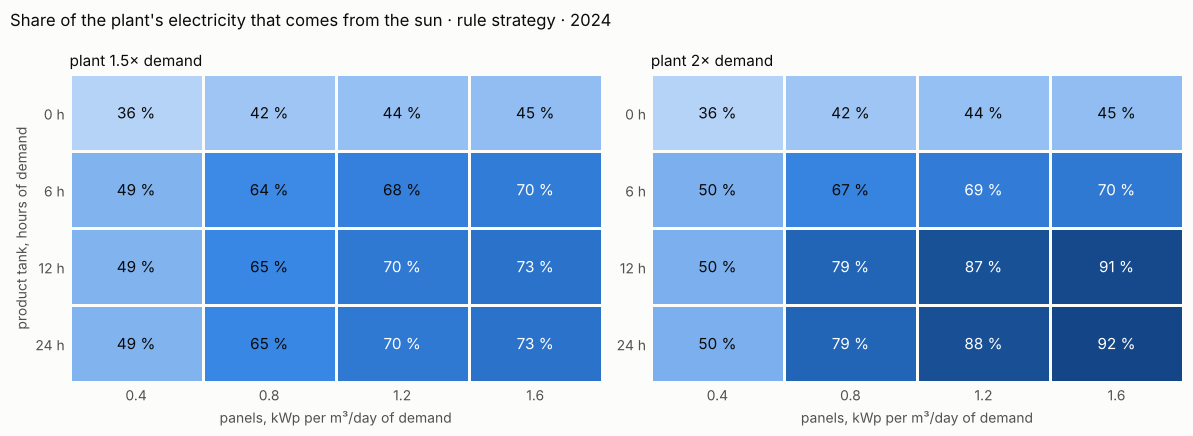

In [13]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, Cx in zip(axes, (1.5, 2.0)):
    cv = curves(Cx)
    grid = np.array([[score(run_rule(pv24 * P * 1000, T24, cv, S * DEMAND), pv24 * P * 1000, T24, cv)["solar share %"]
                      for P in (0.4, 0.8, 1.2, 1.6)] for S in (0, 6, 12, 24)])
    ax.pcolormesh(np.arange(5), np.arange(5), grid, cmap=cmap, vmin=30, vmax=100, edgecolors=SURF, linewidth=2)
    for i in range(4):
        for j in range(4):
            ax.text(j + 0.5, i + 0.5, f"{grid[i, j]:.0f} %", ha="center", va="center", fontsize=11,
                    color="white" if grid[i, j] > 68 else INK)
    ax.set_xticks(np.arange(4) + 0.5, ["0.4", "0.8", "1.2", "1.6"]); ax.set_yticks(np.arange(4) + 0.5, ["0 h", "6 h", "12 h", "24 h"])
    ax.invert_yaxis(); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xlabel("panels, kWp per m³/day of demand"); ax.set_title(f"plant {Cx:g}× demand", loc="left", color=INK, fontsize=11)
axes[0].set_ylabel("product tank, hours of demand")
fig.suptitle("Share of the plant's electricity that comes from the sun · rule strategy · 2024", x=0.01, ha="left", color=INK, fontsize=12)
plt.tight_layout(); plt.show()

### 5c · One summer day and one winter day (rule strategy, the example design)

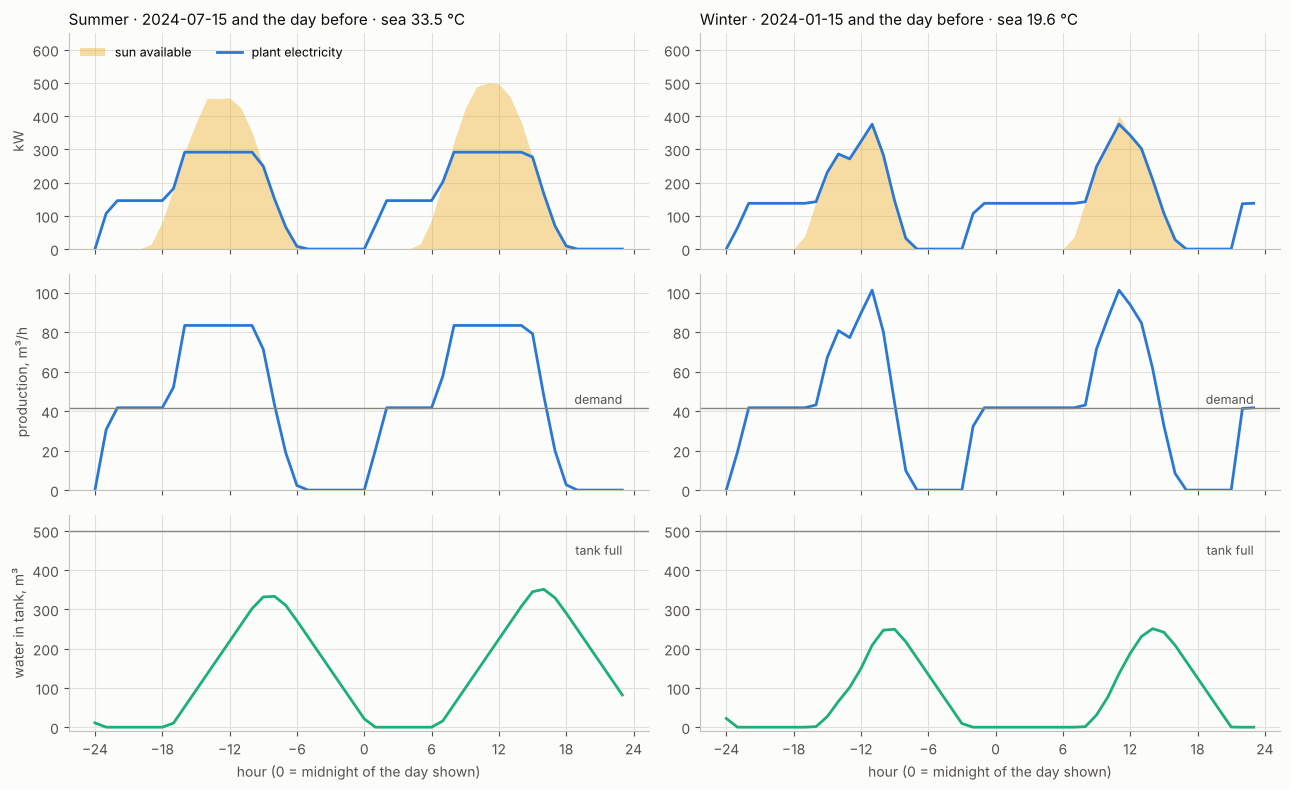

In [14]:
cv = cvC; pv_kw = pv24_kw; S_max = TANK_H * DEMAND
q = q_rule; S = np.cumsum(q - DEMAND); E, _, _ = hourly(q, T24, cv)
fig, axes = plt.subplots(3, 2, figsize=(13, 8), sharex="col")
for j, day in enumerate(("2024-07-15", "2024-01-15")):
    kk = np.where(idx24.strftime("%Y-%m-%d") == day)[0]; kk = np.r_[kk[0] - 24:kk[-1] + 1]; h = np.arange(len(kk)) - 24
    a, b, c = axes[:, j]
    for ax in (a, b, c):
        style(ax)
    a.fill_between(h, pv_kw[kk], color=YELLOW, alpha=0.35, lw=0, label="sun available")
    a.plot(h, E[kk], color=BLUE, lw=2, label="plant electricity")
    a.set_ylim(0, max(pv_kw[kk].max(), E[kk].max()) * 1.3)
    a.set_title(("Summer" if j == 0 else "Winter") + f" · {day} and the day before · sea {T24[kk[-1]]:.1f} °C", loc="left", color=INK, fontsize=11)
    b.plot(h, q[kk], color=BLUE, lw=2); b.axhline(DEMAND, color=MUTED, lw=1); b.text(h[-1], DEMAND + 2, "demand", color=INK2, fontsize=9, ha="right")
    b.set_ylim(0, max(c_["q_max"] for c_ in cv.values()) * 1.08)
    c.plot(h, S[kk], color=AQUA, lw=2); c.axhline(S_max, color=MUTED, lw=1); c.text(h[-1], S_max - 30, "tank full", color=INK2, fontsize=9, ha="right", va="top")
    c.set_ylim(-10, S_max * 1.08); c.set_xticks(np.arange(-24, 25, 6)); c.set_xlabel("hour (0 = midnight of the day shown)")
    if j == 0:
        a.legend(frameon=False, fontsize=9, loc="upper left", ncol=2); a.set_ylabel("kW"); b.set_ylabel("production, m³/h"); c.set_ylabel("water in tank, m³")
for r in range(3):
    lo_, hi_ = min(axes[r, 0].get_ylim()[0], axes[r, 1].get_ylim()[0]), max(axes[r, 0].get_ylim()[1], axes[r, 1].get_ylim()[1])
    axes[r, 0].set_ylim(lo_, hi_); axes[r, 1].set_ylim(lo_, hi_)
plt.tight_layout(); plt.show()

## 6 · The winter cycle: warm the winter feed

A plant beside a power station can mix warm condenser outlet water into its intake. A condenser warms its cooling water by
**5.6–13.9 °C** (10–25 °F; J. P. Guyer, *An Introduction to Condensers and Auxiliary Equipment for Steam Power Plants*, 2023,
after the Unified Facilities Criteria). So the feed can be brought up to a target, never above sea + that rise. When the sea is
already warmer than the target nothing is mixed. Feed temperature = max(sea, min(target, sea + rise)).
The heat it takes = feed volume × density × heat capacity × (feed temperature − sea temperature), with seawater properties from
TEOS-10 (gsw). "Winter" in the table is December to March; the heat is averaged over the whole year's water.

In [15]:
SA = 43.0 / 1.03                                       # absolute salinity, g/kg
CASES = {"no warming": None, "to 25 C, rise up to 5.6": (25.0, 5.6), "to 25 C, rise up to 13.9": (25.0, 13.9),
         "to 29 C, rise up to 13.9": (29.0, 13.9)}
rows = []
for year in range(2015, 2025):
    pv, T_sea, idx = sun_sea(year); winter = np.isin(idx.month, (12, 1, 2, 3))
    for case, spec in CASES.items():
        T = T_sea.copy() if spec is None else np.maximum(T_sea, np.minimum(spec[0], T_sea + spec[1]))
        rho_cp = gsw.rho_t_exact(SA, T_sea, 0) * gsw.cp_t_exact(SA, T_sea, 0)          # J per m3 per K
        for name, cv, q in (("steady", cv1, run_steady(pv, T, cv1, 0)),
                            ("rule", cvC, run_rule(pv * KWP * 1000, T, cvC, TANK_H * DEMAND))):
            s = score(q, pv * KWP * 1000, T, cv)
            E, cp, _ = hourly(q, T, cv)
            keys, k = groups(cv, T); R_h = np.array([cv[float(key)]["R"] for key in keys])[k]
            rows.append(dict(year=year, case=case, plant=name, **s,
                             **{"winter RO kWh/m3": (E - OTHER * 0.40 / R_h * q)[winter].sum() / q[winter].sum(),
                                "winter permeate mg/L": (cp * q)[winter].sum() / q[winter].sum(),
                                "days warmed a year": (T - T_sea > 0.05).sum() / 24,
                                "heat, kWh per m3": np.sum(q / R_h * rho_cp * (T - T_sea)) / 3.6e6 / q.sum()}))
wc = pd.DataFrame(rows)
st = wc[wc.plant == "steady"].groupby("case", sort=False)[["kWh/m3", "winter RO kWh/m3", "winter permeate mg/L", "days warmed a year",
                                                            "heat, kWh per m3"]].mean()
ru = wc[wc.plant == "rule"].groupby("case", sort=False)[["solar share %", "grid kWh/m3"]].mean().add_prefix("solar plant: ")
display(pd.concat([st, ru], axis=1).round(3).T)
base = st.loc["no warming"]
for case in list(CASES)[1:]:
    saved = base["kWh/m3"] - st.loc[case, "kWh/m3"]
    print(f"{case}: saves {saved:.3f} kWh/m3 ({100 * saved / base['kWh/m3']:.1f} %) of electricity for "
          f"{st.loc[case, 'heat, kWh per m3']:.1f} kWh/m3 of heat -> {st.loc[case, 'heat, kWh per m3'] / saved:.0f} kWh of heat per kWh saved")

case,no warming,"to 25 C, rise up to 5.6","to 25 C, rise up to 13.9","to 29 C, rise up to 13.9"
kWh/m3,3.536,3.520,3.518,3.511
winter RO kWh/m3,2.337,2.295,2.288,2.275
winter permeate mg/L,198.442,238.906,247.852,280.467
days warmed a year,0.000,165.788,165.788,216.988
"heat, kWh per m3",0.000,5.532,6.537,12.484
solar plant: solar share %,79.593,79.382,79.338,77.670
solar plant: grid kWh/m3,0.721,0.728,0.729,0.785


to 25 C, rise up to 5.6: saves 0.016 kWh/m3 (0.4 %) of electricity for 5.5 kWh/m3 of heat -> 352 kWh of heat per kWh saved
to 25 C, rise up to 13.9: saves 0.018 kWh/m3 (0.5 %) of electricity for 6.5 kWh/m3 of heat -> 364 kWh of heat per kWh saved
to 29 C, rise up to 13.9: saves 0.025 kWh/m3 (0.7 %) of electricity for 12.5 kWh/m3 of heat -> 503 kWh of heat per kWh saved


## 7 · What each design costs

Only the costs the design changes are counted, per 1,000 m³/day of demand. Chemicals, staff, waste disposal and monitoring
are the same for every design and are left out, so the totals below are the part of the water cost the design decides.
Capital is spread over its life with the capital recovery factor.

| Input | Value | Source |
|---|---|---|
| RO plant, all-in | 1,500 USD per m³/day of capacity (range 1,200–1,800), 2016 USD | World Bank (2019) *The Role of Desalination in an Increasingly Water-Scarce World*, Table ES.1: SWRO in the Arabian Gulf |
| Share of the plant that grows with capacity | 100 % (sensitivity: 30 %, the RO system's share of capital) | assumption; *Capital Cost Elements in the Desalination* (2023), p. 6: RO system 30 % of SWRO capital in four large Gulf projects |
| RO upkeep that grows with capacity | 0.07 USD/m³ at design output: membranes and cartridge filters 0.04 + maintenance 0.03 | World Bank (2019), Table ES.2 |
| Panels | 628 USD per kWp (691 USD per kW AC ÷ our DC/AC ratio 1.1); O&M 10 USD per kWp a year (11 per kW AC ÷ 1.1); 25 years; 2024 USD | IRENA, *Renewable Power Generation Costs in 2024* (2025); IRENA 2025 methodology annex (O&M outside the OECD, 25-year life) |
| Tank | 100 USD/m³, O&M 2 % a year (sensitivity: 750 USD/m³, small welded-steel tanks bid in 2024) | Kocher & Menon (2023) *Energy Environ. Sci.*, SI Table S1 |
| Cost of money | 7.5 % a year (real), 25 years | IRENA's 2024 default for most countries outside the OECD; World Bank (2019): 6–8 % in the region |

The plant costs are in 2016 dollars and the panels in 2024 dollars; a sensitivity row raises the plant costs by the consumer
price index from 2016 to 2024 (× 1.31, Bureau of Labor Statistics). For scale: new gas-fired power costs about
**0.05–0.06 USD/kWh** where gas is cheap and approaches **0.10** where it is expensive (IRENA, *Renewable Power Generation Costs
in 2025*, highlights).

In [16]:
COST = dict(rate=0.075, life=25, ro_capex=1500.0, ro_share=1.0, ro_upkeep=0.07, upkeep_grows=1.0,
            pv_capex=691 / DC_AC, pv_om=11 / DC_AC, tank_capex=100.0, tank_om=0.02)

def crf(i, n):
    return i * (1 + i) ** n / ((1 + i) ** n - 1)

# every design on a grid, every year, rule strategy (fast: well under a minute)
t0 = time.time()
rows = []
for year in range(2015, 2025):
    pv, T, _ = sun_sea(year)
    for Cx in (1.0, 1.25, 1.5, 1.75, 2.0):
        cv = curves(Cx)
        for P in (0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.6, 2.0):
            for S_h in (0, 3, 6, 9, 12, 18, 24):
                s = score(run_rule(pv * P * 1000, T, cv, S_h * DEMAND), pv * P * 1000, T, cv)
                rows.append(dict(year=year, capacity=Cx, kwp=P, tank_h=S_h, water=s["water m3"], energy=s["energy kWh"], grid=s["grid kWh"]))
G = pd.DataFrame(rows).groupby(["capacity", "kwp", "tank_h"]).mean().reset_index()
G["solar share %"] = 100 * (1 - G.grid / G.energy)
print(f"{len(rows)} runs in {time.time() - t0:.0f} s")

def costs_per_m3(x, price):
    a = pd.DataFrame(index=G.index)
    a["RO plant"] = crf(x["rate"], x["life"]) * x["ro_capex"] * 1000 * (1 + x["ro_share"] * (G.capacity - 1))
    a["RO upkeep"] = x["ro_upkeep"] * 1000 * 365 * (1 + x["upkeep_grows"] * (G.capacity - 1))
    a["panels"] = (crf(x["rate"], x["life"]) * x["pv_capex"] + x["pv_om"]) * G.kwp * 1000
    a["tank"] = (crf(x["rate"], x["life"]) + x["tank_om"]) * x["tank_capex"] * G.tank_h * DEMAND
    a["grid electricity"] = price * G.grid
    return a.div(G.water, axis=0)

def find(cap, kwp, tank_h):
    return G[(G.capacity == cap) & (G.kwp == kwp) & (G.tank_h == tank_h)].index[0]

GRID_ONLY, EXAMPLE, EXAMPLE_NO_TANK = find(1.0, 0.0, 0), find(CAP, KWP, TANK_H), find(1.0, KWP, 0)
NORMAL = (G.capacity == 1.0).to_numpy()
parts = costs_per_m3(COST, 0.10).loc[[GRID_ONLY, EXAMPLE_NO_TANK, EXAMPLE]]
parts.index = ["grid only", "same panels, normal plant, no tank", "example design (2x plant, 0.8 kWp, 12 h)"]
parts["total"] = parts.sum(axis=1)
print("USD per m3 at a grid price of 0.10 USD/kWh")
display(parts.round(3))

3150 runs in 17 s
USD per m3 at a grid price of 0.10 USD/kWh


,RO plant,RO upkeep,panels,tank,grid electricity,total
grid only,0.368,0.07,0.000,0.000,0.354,0.792
"same panels, normal plant, no tank",0.368,0.07,0.145,0.000,0.207,0.791
"example design (2x plant, 0.8 kWp, 12 h)",0.737,0.14,0.145,0.015,0.072,1.109


In [17]:
FINE = np.round(np.arange(0.01, 0.601, 0.001), 3)

def cheapest(x):
    """Price by price: the cheapest design, and where a few things first happen."""
    out = []
    for p in FINE:
        c = costs_per_m3(x, p).sum(axis=1); k = c.idxmin()
        out.append(dict(price=p, k=k, cost=c[k], normal_best=c[NORMAL].min(), example=c[EXAMPLE], grid_only=c[GRID_ONLY]))
    return pd.DataFrame(out)

def first(d, cond):
    hit = d[cond(d)]
    return float(hit.price.iloc[0]) if len(hit) else float("nan")

def label(k):
    return f"{G.capacity[k]:g}x, {G.kwp[k]:g} kWp, {G.tank_h[k]:g} h ({G['solar share %'][k]:.0f} % sun)"

base = cheapest(COST)
steps = base[base.k != base.k.shift()]
print("The cheapest design as the grid price rises (base case):")
for _, r in steps.iterrows():
    print(f"  from {r.price:.3f} USD/kWh: {label(r.k)}")

The cheapest design as the grid price rises (base case):
  from 0.010 USD/kWh: 1x, 0 kWp, 0 h (0 % sun)
  from 0.042 USD/kWh: 1x, 0.2 kWp, 0 h (25 % sun)
  from 0.078 USD/kWh: 1x, 0.4 kWp, 3 h (40 % sun)
  from 0.218 USD/kWh: 1x, 0.6 kWp, 3 h (44 % sun)
  from 0.329 USD/kWh: 1.25x, 0.8 kWp, 6 h (57 % sun)
  from 0.360 USD/kWh: 1.5x, 1 kWp, 9 h (69 % sun)
  from 0.372 USD/kWh: 1.75x, 1.2 kWp, 12 h (80 % sun)
  from 0.395 USD/kWh: 2x, 1.2 kWp, 18 h (89 % sun)
  from 0.536 USD/kWh: 2x, 1.6 kWp, 18 h (92 % sun)


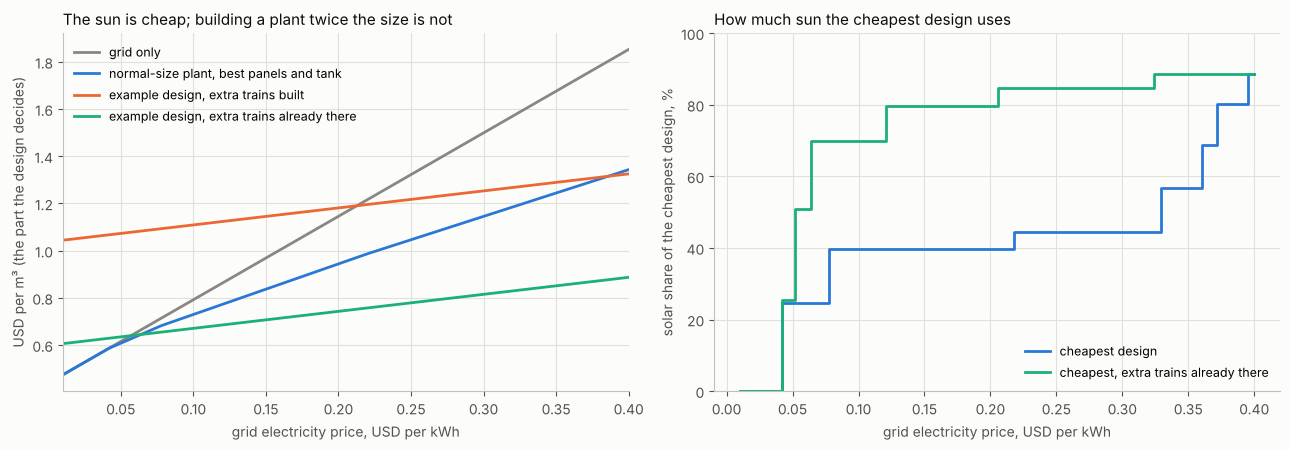

In [18]:
SPARE = {**COST, "ro_share": 0.0, "upkeep_grows": 0.0}          # the extra trains are already there, upkeep already paid
spare = cheapest(SPARE)
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.6)); style(a); style(b)
P40 = base.price <= 0.40
for y, col, name in ((base.grid_only, MUTED, "grid only"), (base.normal_best, BLUE, "normal-size plant, best panels and tank"),
                     (base.example, ORANGE, "example design, extra trains built"), (spare.example, AQUA, "example design, extra trains already there")):
    a.plot(base.price[P40], y[P40], color=col, lw=2, label=name)
a.legend(frameon=False, fontsize=9, loc="upper left")
a.set_xlim(0.01, 0.40); a.set_xlabel("grid electricity price, USD per kWh"); a.set_ylabel("USD per m³ (the part the design decides)")
a.set_title("The sun is cheap; building a plant twice the size is not", loc="left", color=INK, fontsize=11)
for d, col, name in ((base, BLUE, "cheapest design"), (spare, AQUA, "cheapest, extra trains already there")):
    b.plot(d.price[P40], G["solar share %"].to_numpy()[d.k[P40].to_numpy()], color=col, lw=2, label=name, drawstyle="steps-post")
b.set_xlabel("grid electricity price, USD per kWh"); b.set_ylabel("solar share of the cheapest design, %"); b.set_ylim(0, 100)
b.legend(frameon=False, fontsize=9, loc="lower right")
b.set_title("How much sun the cheapest design uses", loc="left", color=INK, fontsize=11)
plt.tight_layout(); plt.show()

In [19]:
CASES_COST = {"base": {}, "only the RO system grows (30 %)": {"ro_share": 0.30}, "RO plant 1,200 USD per m3/d": {"ro_capex": 1200.0},
              "RO plant 1,800 USD per m3/d": {"ro_capex": 1800.0}, "plant costs in 2024 USD (x 1.31)": {"ro_capex": 1500.0 * 1.31, "ro_upkeep": 0.07 * 1.31},
              "cost of money 5 %": {"rate": 0.05}, "small steel tank, 750 USD/m3": {"tank_capex": 750.0},
              "extra trains already there": {"ro_share": 0.0, "upkeep_grows": 0.0},
              "extra trains there, their upkeep counted": {"ro_share": 0.0, "upkeep_grows": 1.0}}
out = {}
for name, change in CASES_COST.items():
    x = {**COST, **change}; d = cheapest(x)
    big = d[G.capacity.to_numpy()[d.k.to_numpy()] > 1.0]
    row = {"panels first pay, USD/kWh": first(d, lambda z: G.kwp.to_numpy()[z.k.to_numpy()] > 0),
           "a bigger plant is cheapest from, USD/kWh": float(big.price.iloc[0]) if len(big) else float("nan"),
           "example design beats every normal-size plant from, USD/kWh": first(d, lambda z: z.example <= z.normal_best)}
    for p in (0.05, 0.10, 0.15, 0.20, 0.30):
        row[f"cheapest at {p:.2f}"] = label(int(d.loc[(d.price - p).abs().idxmin(), "k"]))
    out[name] = row
display(pd.DataFrame(out))

,base,only the RO system grows (30 %),"RO plant 1,200 USD per m3/d","RO plant 1,800 USD per m3/d",plant costs in 2024 USD (x 1.31),cost of money 5 %,"small steel tank, 750 USD/m3",extra trains already there,"extra trains there, their upkeep counted"
"panels first pay, USD/kWh",0.042,0.042,0.042,0.042,0.042,0.035,0.042,0.042,0.042
"a bigger plant is cheapest from, USD/kWh",0.329,0.173,0.289,0.37,0.404,0.271,0.383,0.01,0.077
"example design beats every normal-size plant from, USD/kWh",0.386,0.186,0.328,0.447,0.5,0.318,0.447,0.064,0.108
cheapest at 0.05,"1x, 0.2 kWp, 0 h (25 % sun)","1x, 0.2 kWp, 0 h (25 % sun)","1x, 0.2 kWp, 0 h (25 % sun)","1x, 0.2 kWp, 0 h (25 % sun)","1x, 0.2 kWp, 0 h (25 % sun)","1x, 0.2 kWp, 0 h (25 % sun)","1x, 0.2 kWp, 0 h (25 % sun)","1.75x, 0.2 kWp, 0 h (25 % sun)","1x, 0.2 kWp, 0 h (25 % sun)"
cheapest at 0.10,"1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 0 h (36 % sun)","2x, 0.6 kWp, 9 h (70 % sun)","1.25x, 0.4 kWp, 3 h (45 % sun)"
cheapest at 0.15,"1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 0 h (36 % sun)","2x, 0.8 kWp, 12 h (80 % sun)","2x, 0.8 kWp, 12 h (80 % sun)"
cheapest at 0.20,"1x, 0.4 kWp, 3 h (40 % sun)","1.75x, 0.8 kWp, 9 h (73 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.4 kWp, 3 h (40 % sun)","1x, 0.6 kWp, 3 h (44 % sun)","1x, 0.4 kWp, 0 h (36 % sun)","2x, 0.8 kWp, 12 h (80 % sun)","2x, 0.8 kWp, 12 h (80 % sun)"
cheapest at 0.30,"1x, 0.6 kWp, 3 h (44 % sun)","2x, 1 kWp, 12 h (85 % sun)","1.25x, 0.8 kWp, 6 h (57 % sun)","1x, 0.6 kWp, 3 h (44 % sun)","1x, 0.6 kWp, 3 h (44 % sun)","1.5x, 1 kWp, 9 h (69 % sun)","1x, 0.6 kWp, 3 h (44 % sun)","2x, 1 kWp, 12 h (85 % sun)","2x, 1 kWp, 12 h (85 % sun)"


## What it means

- **Without a tank the sun covers under half the electricity** (36–45 % in 2024 with 0.4–1.6 kWp per m³/day): a plant that
  makes water at the demand rate can only use the sun while it shines.
- **Following the sun needs spare capacity and a tank.** A plant twice the demand with a 12-hour tank and 0.8 kWp per m³/day gets
  about 80 % of its electricity from the sun (79.6 % on average over 2015–2024; 77.6–81.9 % by year), and 91 % with 1.6 kWp
  (2024). The tank holds the water made above demand by day, so a bigger plant needs a bigger tank; beyond that, more tank adds little.
- **The process efficiency barely moves.** The sun-following plant uses 3.53 kWh/m³ against 3.54 for the steady plant of the
  demand's size. The same 2× plant run steadily would use 3.40 kWh/m³ (its trains at low flux): following the sun gives up about
  4 % of efficiency in exchange for the sun.
- **A forecast adds nothing here.** In 2024 the simple rule bought as little grid energy as the best possible schedule, worked out
  with the whole year known (0.7331 against 0.7330 kWh/m³). Planning with "tomorrow = today" does worse (75.8 % sun against
  79.6 %), because it fixes the day's output at midnight. The plans' only gain is fewer train starts (5.6–5.7 a day against 7.85),
  bought with the switching penalty. Time-of-day prices or batteries could change this — not tested here.
- **Summer limits the plant.** At 33 °C a train has a single usable point at 40 % recovery (14 LMH). At 35 °C that point breaks
  both lead-element limits, so the hottest days run at 35 % recovery, which opens the window again (9–16 LMH) at the cost of
  more intake and pretreatment energy. The plant follows the summer sun by switching whole trains, and the surplus midday sun is lost.
- **Product water** stays under 500 mg/L: 255–270 mg/L on average, but 490 mg/L in the worst hour of the ten years (a new
  membrane in the hottest water, at 35 % recovery and the lowest flux) — close to the limit.
- **Winter cycle:** even with free condenser heat, warming the feed to 25 °C saves only 0.4–0.5 % of the plant's electricity
  (about 2 % of the RO's from December to March), makes the winter water saltier (199 → 239–248 mg/L) and lowers the solar
  plant's share slightly (79.6 → 79.3–79.4 %). Warming to 29 °C saves 0.7 % but makes the solar plant buy 9 % more from the grid.
  Without free heat it never pays: 350–500 kWh of heat for each kWh of electricity saved.
- **Costs: the sun is cheap, a bigger plant is not.** Panels pay once grid power costs more than 0.042 USD/kWh. From 0.078 to
  0.33 USD/kWh the cheapest new plant is the demand's size with 0.4–0.6 kWp per m³/day and a 3-hour tank: 40–44 % sun (the tank
  uses the extra output the trains can give in cold water). A bigger plant becomes the cheapest only from 0.33 USD/kWh, and the
  2× example beats every normal-size plant only from 0.39 (0.19 if only the RO system has to grow; 0.50 with the plant costs in
  2024 dollars). **If the extra trains already exist** and their upkeep is paid anyway, using them to follow the sun is the
  cheapest choice from about 0.05 USD/kWh, with 70 % sun from 0.064 and 80 % from 0.12; counting their upkeep, from about 0.08,
  and 80 % sun from 0.12.

**Not in this model:** dust on the panels and panel ageing; membrane fouling and ageing (phases 1 and 3); the wear of starting and
stopping trains (the rule starts each train about once a day); mixing and leakage in the energy-recovery device, drive losses and
the pump suction pressure; NaCl standing in for seawater; the rest of the plant as a fixed amount per m³ made (if 0.1 kWh/m³ of it
ran at the demand rate, the solar share would fall by about 1 point, section 5a); 100 % plant availability; the sea temperature
is NASA POWER's skin temperature over a 0.5° × 0.625° box, read on a 2 °C table, not a measured intake temperature; surplus sun
earns nothing.

*FilmTec™ and SW30HRLE are trademarks owned by affiliates of DuPont de Nemours, Inc. They are named here only to identify the
public documents the model uses; this notebook is not connected with or endorsed by the company.*